In [21]:
import os
import yaml
import uproot
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt


In [22]:
output_dir = '../output/notebooks/prompt_secondary'
if not os.path.exists(output_dir):
    print(f'creating {output_dir}')
    os.makedirs(output_dir)

# Load Skimming Datasets

Load data and MC

In [23]:
data_samples = yaml.safe_load(open('../data/testing_ap.yaml', 'r'))
event_id_ds = [23173002, 23173003] #23173002 = secondary, 23173003 = prompt

sample_MC_ds = uproot.open(data_samples[f'mc-{event_id_ds[0]}'][0])
keys_ds_MC = sample_MC_ds['Ds2PhiPi/DecayTree'].keys()

hlt1_tos_var_ds = [k for k in keys_ds_MC if 'Hlt1' in k and 'TOS' in k]
hlt1_tis_var_ds = [k for k in keys_ds_MC if 'Hlt1' in k and 'TIS' in k]
bkg_ds = ['Ds_BKGCAT']
M_ds = ['Ds_M']           
kin_ds = ['Ds_PT', 'Ds_ETA', 'Ds_MINPT', 'Ds_MAXPT', 'Ds_SUMPT', 'mup_PT', 'mum_PT', 'pi_PT', 'Ds_P']
topo_ds = ['Ds_VCHI2DOF', 'Ds_BPVIPCHI2', 'Ds_BPVVDRHO', 'Ds_BPVIP', 'Ds_LOGBPVIPCHI2', 'Ds_MAXDOCA', 'Ds_MAXSDOCA', 'Ds_BPVFD', 'Ds_DTF_PV_CTAU']
isolation_ds = ['Ds_HEAD_LongTrack_0.5_PTASY', 'Ds_HEAD_LongTrack_0.5_CPT', 'Ds_HEAD_LongTrack_1.0_CMULT', 'Ds_LONGTRACK_ISOLATION_v2_isomin3', 'Ds_LONGTRACK_ISOLATION_v3_isomin3', 'Ds_LONGTRACK_ISOLATION_Run2_mum_MVA', 'Ds_LONGTRACK_ISOLATION_Run2_mup_MVA', 'Ds_LONGTRACK_ISOLATION_mup_MVA', 'Ds_LONGTRACK_ISOLATION_mum_MVA']

variables_ds = hlt1_tos_var_ds + hlt1_tis_var_ds + M_ds + kin_ds + topo_ds + isolation_ds


data_np = uproot.open(data_samples['data'][0])['Ds2PhiPi/DecayTree'].arrays(variables_ds, library="np")
df_data_ds = pd.DataFrame(data_np)

df_mc_ds_list = []
for event in event_id_ds:
    MC_np_ds = uproot.open(data_samples[f'mc-{event}'][0])['Ds2PhiPi/DecayTree'].arrays(variables_ds + bkg_ds, library="np")
    MC_df_ds = pd.DataFrame(MC_np_ds) 
    
    #tag to distinguish prompt and secondary MC
    MC_df_ds['is_prompt'] = 1 if event == 23173003 else 0
    df_mc_ds_list.append(MC_df_ds)
    
df_MC_ds = pd.concat(df_mc_ds_list, ignore_index=True)
df_MC_ds = df_MC_ds[df_MC_ds['Ds_BKGCAT'] <= 50]

Trigger and Pre-selection tags

In [24]:
def trigger_filter(df): 
    if 'Tau_Hlt1DiMuonDisplacedDecision_TOS' in df.columns:
        prefix = 'Tau'
    elif 'Ds_Hlt1DiMuonDisplacedDecision_TOS' in df.columns:
        prefix = 'Ds'
    else:
        raise KeyError("Error")

    col_1 = f'{prefix}_Hlt1DiMuonDisplacedDecision_TOS'
    col_2 = f'{prefix}_Hlt1TwoTrackMVADecision_TOS'

    mask1 = df[col_1].astype(bool)                                                                                                           
    mask2 = df[col_2].astype(bool)
    return df[mask1 | mask2].copy()

df_data_ds = trigger_filter(df_data_ds) 
df_MC_ds = trigger_filter(df_MC_ds)

#selection cut
cut_vchi2 = 6.312
df_MC_ds = df_MC_ds[df_MC_ds['Ds_VCHI2DOF'] < cut_vchi2].copy()
df_data_ds = df_data_ds[df_data_ds['Ds_VCHI2DOF'] < cut_vchi2].copy()

Mass fit and sWeights

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 6.522953033447266
CPU Time  = 6.519999999999996
Fit results saved in ../output/notebooks/prompt_secondary/ds_data_fit_presel.res


Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.18017196655273438
CPU Time  = 0.18000000000000682
Signal = 9527, Bkg = 6082
Running fit in "Silent" mode
w_n_sig array('f', [0.0]) 0.0 float f
w_n_bkg array('f', [0.0]) 0.0 float f
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::Ds_M
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sig_mc_m1
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::sig_mc_s1
[#0] WARNING:InputArguments -- The parameter 'sig_mc_s1' with range [0, 100] of the RooGaussian 'sig_mc_g1' exceeds the safe range of (0, inf). Advise to limit its range.
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooGaussian::sig_mc_g1
[#1] INFO:ObjectHandling 

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 193.782 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       267835.5174 Edm =       653.1949862 NCalls =     35
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 267835.5174
  Edm           : 653.1949862
  Internal parameters:	[                0                0      0.927295218                0                0     -0.927295218     -0.927295218]	
  Internal gradient  :	[     -325.3225151     -2537.342891       1381.10085      206.7520509      13895.90487      806.2438006     -22910.47387]	
  Internal covariance matrix:
[[  0.00090023071              0              0              0              0              0              0]
 [              0  1.4117026e-05              0              0              0              0              0]
 [              0              0  0.00067088281              0       

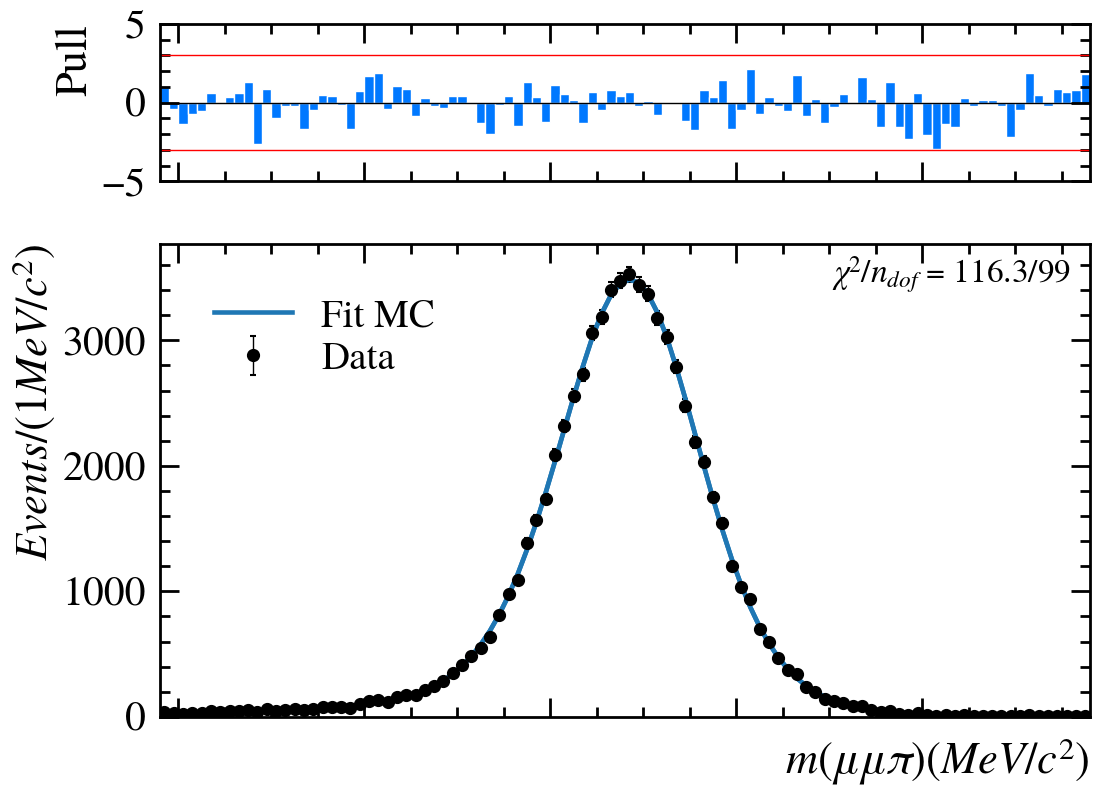

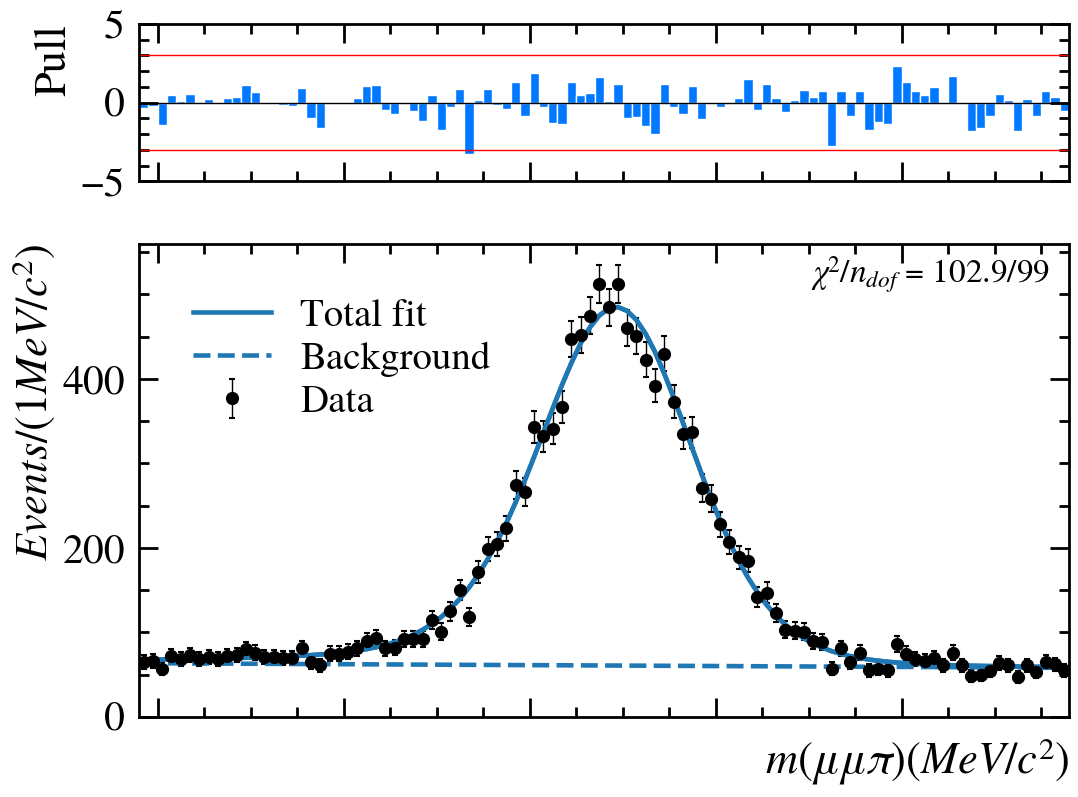

In [25]:
from analysis_helpers.fit import FitModels, FitUtils, add_to_workspace
from analysis_helpers.root_helpers import import_root_with_proxy
import numpy as np

r, _HAS_ROOT = import_root_with_proxy()
fm = FitModels()
fu = FitUtils()

m_min, m_max = 1918, 2018

#MC
mask_mc = (df_MC_ds['Ds_M'] > m_min) & (df_MC_ds['Ds_M'] < m_max)  
m_mc = df_MC_ds.loc[mask_mc, 'Ds_M'].values
#Real Data
mask_data = (df_data_ds['Ds_M'] > m_min) & (df_data_ds['Ds_M'] < m_max)
m_data = df_data_ds.loc[mask_data, 'Ds_M'].values

ws = fm.simple_workspace('Ds_M', m_min, m_max, 'm(#mu#mu#pi)', 'MeV/c^{2}')
Ds_M = ws.var('Ds_M')

data_mc = fu.DatasetFromNumpy(m_mc, Ds_M)
data_real = fu.DatasetFromNumpy(m_data, Ds_M)

# Fit MC
sig_mc = fm.JohnsonPlusGaussian(ws, 'sig_mc', 'Ds_M')

res_mc = fu.fit_to_data(sig_mc, data_mc)
res_mc.Print()

mc_params = sig_mc.getParameters(r.RooArgSet(Ds_M))
for var in mc_params:
    var.setConstant(True)

#plot mc
frame_mc = Ds_M.frame(r.RooFit.Title("Fit MC"))
data_mc.plotOn(frame_mc)
sig_mc.plotOn(frame_mc)
sig_mc.plotOn(frame_mc) 
fig_mc, ax_mc = fu.plot_fit_and_residuals_mpl(frame_mc, labels=['Data', 'Fit MC'])

# Fit Data
lam = add_to_workspace(ws, r.RooRealVar('lam', 'lam', -0.001, -1.0, 0.0))
bkg = add_to_workspace(ws, r.RooExponential('bkg', 'bkg', Ds_M, lam))

#Number events variables
n_sig = add_to_workspace(ws, r.RooRealVar('n_sig', 'n_sig', len(m_data)*0.5, 0, len(m_data)*2))
n_bkg = add_to_workspace(ws, r.RooRealVar('n_bkg', 'n_bkg', len(m_data)*0.5, 0, len(m_data)*2))

model_data = add_to_workspace(ws, r.RooAddPdf('model_data', 'model_data', [sig_mc, bkg], [n_sig, n_bkg]))

#free parameters
for p_name in ['sig_mc_m1','sig_mc_s1','lam']: 
    var = ws.var(p_name)
    if var:
        var.setConstant(False)

fu.safe_read_roofit_vars(ws, f'{output_dir}/ds_data_fit_presel.txt')
res_data = fu.fit_to_data(model_data, data_real, outname=f'{output_dir}/ds_data_fit_presel')
ws.allVars().writeToFile(f'{output_dir}/ds_data_fit_presel.txt')
fu.AddFitInfo(f'{output_dir}/ds_data_fit_presel.txt', res_data)
print(f"Signal = {n_sig.getVal():.0f}, Bkg = {n_bkg.getVal():.0f}")

#plot
frame_data = Ds_M.frame(r.RooFit.Title("Fit Data Post-Selection"))
data_real.plotOn(frame_data)
model_data.plotOn(frame_data)
model_data.plotOn(frame_data, r.RooFit.Components("bkg"), r.RooFit.LineStyle(r.kDashed))
model_data.plotOn(frame_data) #for pulls
fig_data, ax_data = fu.plot_fit_and_residuals_mpl(frame_data, labels=['Data', 'Total fit', 'Background'])
fig_data.savefig(f'{output_dir}/ds_data_fit_presel.png', dpi=300)

#sWeights
sw = fu.Sweights(ws, 'Ds_M', data_real, model_data.GetName(), 
                 pdfs=[sig_mc.GetName(), bkg.GetName()], nevs=[n_sig.GetName(), n_bkg.GetName()], verbose=False)

#signal weights
sw_sig_np = np.array([sw["vars"]["w_n_sig"][0] for i in range(sw["tree"].GetEntries()) for _ in [sw["tree"].GetEntry(i)]])

df_data_ds['sWeight'] = 0.0
df_data_ds.loc[mask_data, 'sWeight'] = sw_sig_np

# Prompt and secondary

In [26]:
var_name = 'Ds_LOGBPVIPCHI2'
v_min, v_max = -10.0, 6.0

ws_ip = fm.SimpleWorkspace(obsname=var_name, xmin=v_min, xmax=v_max, title='LOGBPVIPCHI2', unit='')
log_ip = ws_ip.var(var_name)

df_mc_fit = df_MC_ds[(df_MC_ds[var_name] >= v_min) & (df_MC_ds[var_name] <= v_max)]
df_data_fit = df_data_ds[(df_data_ds[var_name] >= v_min) & (df_data_ds[var_name] <= v_max)]

#MC Prompt, Secondary e Tot
vals_mcp = df_mc_fit.loc[df_mc_fit['is_prompt'] == 1, var_name].values
data_mcp = fu.DatasetFromNumpy(vals_mcp, log_ip)

vals_mcs = df_mc_fit.loc[df_mc_fit['is_prompt'] == 0, var_name].values
data_mcs = fu.DatasetFromNumpy(vals_mcs, log_ip)

vals_mc_tot = df_mc_fit[var_name].values
data_mc_tot = fu.DatasetFromNumpy(vals_mc_tot, log_ip)

#Real-Data sWeighted
weight_var = r.RooRealVar("sWeight", "sWeight", -100, 100)
data_sweight = r.RooDataSet("data_sweight", "data_sweight", r.RooArgSet(log_ip, weight_var), r.RooFit.WeightVar("sWeight"))

for val, w in zip(df_data_fit[var_name].values, df_data_fit['sWeight'].values):
    log_ip.setVal(val)
    weight_var.setVal(w)
    data_sweight.add(r.RooArgSet(log_ip, weight_var), w)

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::Ds_LOGBPVIPCHI2


Fit on MC to fix the shape Johnson

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 6.542853832244873
CPU Time  = 6.57


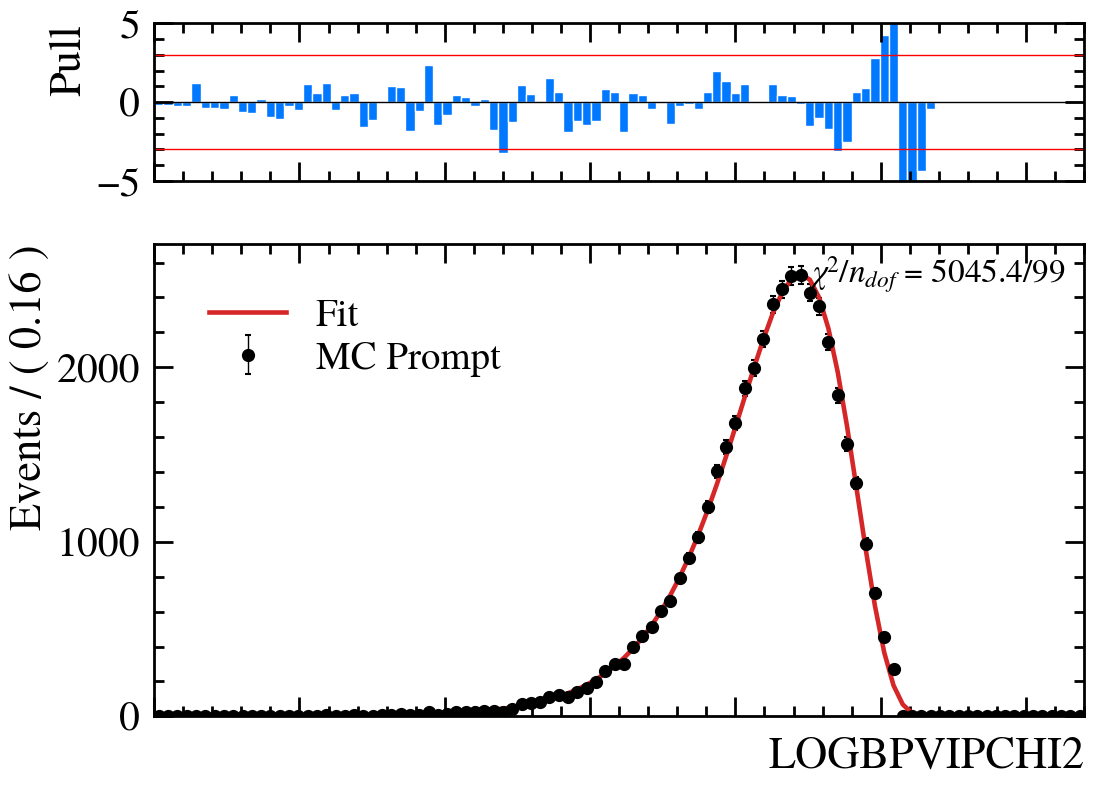

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 1.0917859077453613
CPU Time  = 1.0900000000000034


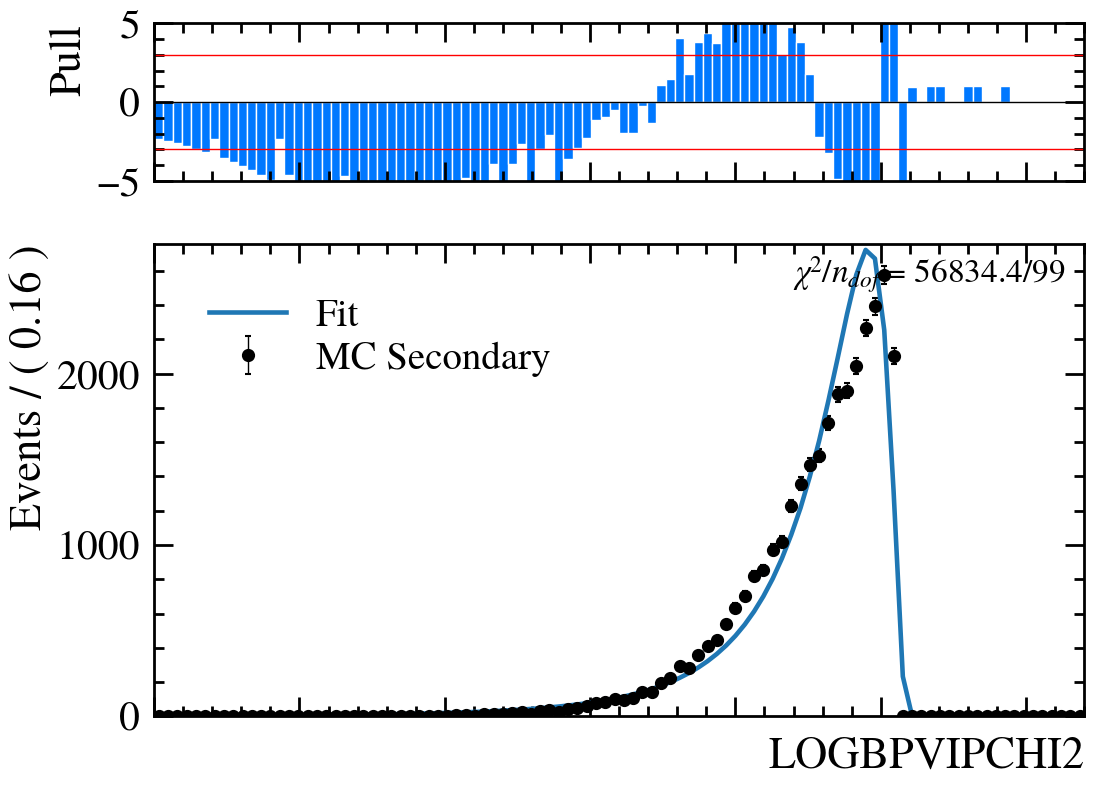

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_mJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_sJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_gammaJsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::prompt_mc_deltaJsu
[#0] WARNING:InputArguments -- The parameter 'prompt_mc_sJsu' with range [0, 16] of the RooJohnson 'prompt_mc_jsu' exceeds the safe range of (0, inf). Advise to limit its range.
[#0] WARNING:InputArguments -- The parameter 'prompt_mc_deltaJsu' with range [0, 5] of the RooJohnson 'prompt_mc_jsu' exceeds the safe range of (0, inf). Advise to limit its range.
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::prompt_mc_jsu
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::prompt_mc_jsu
[#1] INFO:ObjectHandling -- RooWorkspace

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 56.9202 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       90181.55288 Edm =       38977.74389 NCalls =     17
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 90181.55288
  Edm           : 38977.74389
  Internal parameters:	[    -0.5253334297                0                0    -0.7500586627]	
  Internal gradient  :	[      137064.1913     -257068.8067      73550.02348      -133243.792]	
  Internal covariance matrix:
[[  3.4739414e-06              0              0              0]
 [              0  4.6068016e-07              0              0]
 [              0              0  3.1521129e-06              0]
 [              0              0              0  2.4305638e-06]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 2000
Info in <Minuit2>: VariableMet

In [ ]:
#FITTING MC PROMPT 
pdf_prompt_mc = fm.Johnson(ws_ip, 'prompt_mc', var_name)

ws_ip.var('prompt_mc_mJsu').setRange(-2.0, 4.0)
ws_ip.var('prompt_mc_sJsu').setRange(0.01, 10.0)
ws_ip.var('prompt_mc_gammaJsu').setRange(-10.0, 10.0)
ws_ip.var('prompt_mc_deltaJsu').setRange(0.01, 10.0)

ws_ip.var('prompt_mc_mJsu').setVal(1.0) 
fu.fit_to_data(pdf_prompt_mc, data_mcp, kSilent=False)

#plot
frame_p = log_ip.frame(r.RooFit.Title(""))
data_mcp.plotOn(frame_p)
pdf_prompt_mc.plotOn(frame_p, r.RooFit.LineColor(r.kRed))
fig_p, ax_p = fu.plot_fit_and_residuals_mpl(frame_p, labels=['MC Prompt', 'Fit'])
plt.show()

for p in ['prompt_mc_gammaJsu', 'prompt_mc_deltaJsu', 'prompt_mc_mJsu', 'prompt_mc_sJsu']:
    ws_ip.var(p).setConstant(True)


#FITTING MC SECONDARY
pdf_sec_mc = fm.Johnson(ws_ip, 'sec_mc', var_name)

ws_ip.var('sec_mc_mJsu').setRange(1.0, 7.0)
ws_ip.var('sec_mc_sJsu').setRange(0.01, 10.0)
ws_ip.var('sec_mc_gammaJsu').setRange(-10.0, 10.0)
ws_ip.var('sec_mc_deltaJsu').setRange(0.01, 10.0)

ws_ip.var('sec_mc_mJsu').setVal(4.5) 
fu.fit_to_data(pdf_sec_mc, data_mcs, kSilent=False)
#plot
frame_s = log_ip.frame(r.RooFit.Title(""))
data_mcs.plotOn(frame_s)
pdf_sec_mc.plotOn(frame_s, r.RooFit.LineColor(r.kBlue))
fig_s, ax_s = fu.plot_fit_and_residuals_mpl(frame_s, labels=['MC Secondary', 'Fit'])
plt.show()

for p in ['sec_mc_gammaJsu', 'sec_mc_deltaJsu', 'sec_mc_mJsu', 'sec_mc_sJsu']:
    ws_ip.var(p).setConstant(True)

Fit combined on MC

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.05951285362243652
CPU Time  = 0.07000000000000028


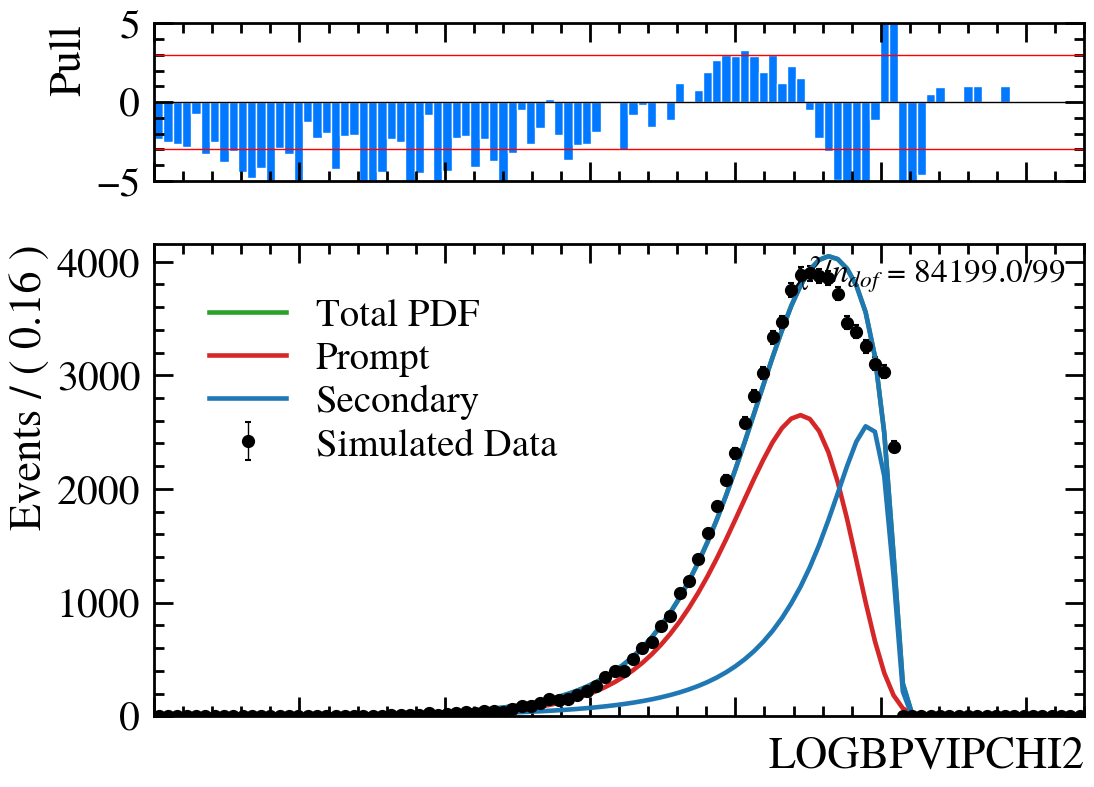

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::frac_prompt_mc
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooJohnson::prompt_mc_jsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_mJsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_sJsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_gammaJsu for import of RooAddPdf::model_mc_tot
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_deltaJsu for imp

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 14.4441 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       118011.9285 Edm =       279.2029749 NCalls =      5
Info in <Minuit2>: MnSeedGenerator Initial state  
  Minimum value : 118011.9285
  Edm           : 279.2029749
  Internal parameters:	[     0.4115168461]	
  Internal gradient  :	[      2837.220267]	
  Internal covariance matrix:
[[  0.00013873752]]]
Info in <Minuit2>: VariableMetricBuilder Start iterating until Edm is < 0.001 with call limit = 500
Info in <Minuit2>: VariableMetricBuilder    0 - FCN =       118011.9285 Edm =       279.2029749 NCalls =      5
Info in <Minuit2>: VariableMetricBuilder    1 - FCN =       117734.6341 Edm =     0.01197892347 NCalls =      8
Info in <Minuit2>: VariableMetricBuilder    2 - FCN =       117734.6221 Edm =   7.017357525e-07 NCalls =     11
Info in <Minuit2>: MnHesse Done af

In [28]:
frac_prompt_mc = add_to_workspace(ws_ip, r.RooRealVar("frac_prompt_mc", "frac_prompt_mc", 0.7, 0.0, 1.0))
model_mc_tot = add_to_workspace(ws_ip, r.RooAddPdf("model_mc_tot", "Total MC PDF", [pdf_prompt_mc, pdf_sec_mc], [frac_prompt_mc]))

fu.fit_to_data(model_mc_tot, data_mc_tot, kSilent=False)

#plot MC
frame_mc = log_ip.frame(r.RooFit.Title(""))
data_mc_tot.plotOn(frame_mc)
model_mc_tot.plotOn(frame_mc, r.RooFit.LineColor(r.kGreen))
model_mc_tot.plotOn(frame_mc, r.RooFit.Components("prompt_mc_jsu"), r.RooFit.LineColor(r.kRed))
model_mc_tot.plotOn(frame_mc, r.RooFit.Components("sec_mc_jsu"), r.RooFit.LineColor(r.kBlue))
model_mc_tot.plotOn(frame_mc) 
fig_mc, ax_mc = fu.plot_fit_and_residuals_mpl(frame_mc, labels=['Simulated Data', 'Total PDF', 'Prompt', 'Secondary'])
plt.show()

Fit on data sweighted

Fit Result
Fit status = 0
Minuit status = 3
Number of Loops = 2
Real Time  = 0.3917100429534912
CPU Time  = 0.39000000000000057


/user/gr1/lhcb/limpicciche/tesi_impicciche/tesi-env/lib/python3.11/site-packages/analysis_helpers/fit.py:819: RuntimeWarning: invalid value encountered in sqrt
  mplhep.histplot(his,yerr=np.sqrt(his[0]),histtype='errorbar',color='black',label='data' if labels is None else labels[0],ax=ax2)
/user/gr1/lhcb/limpicciche/tesi_impicciche/tesi-env/lib/python3.11/site-packages/analysis_helpers/fit.py:759: RuntimeWarning: invalid value encountered in sqrt
  data_err = np.sqrt(data_counts) if poisson else np.sqrt(data_counts) # to be fixed


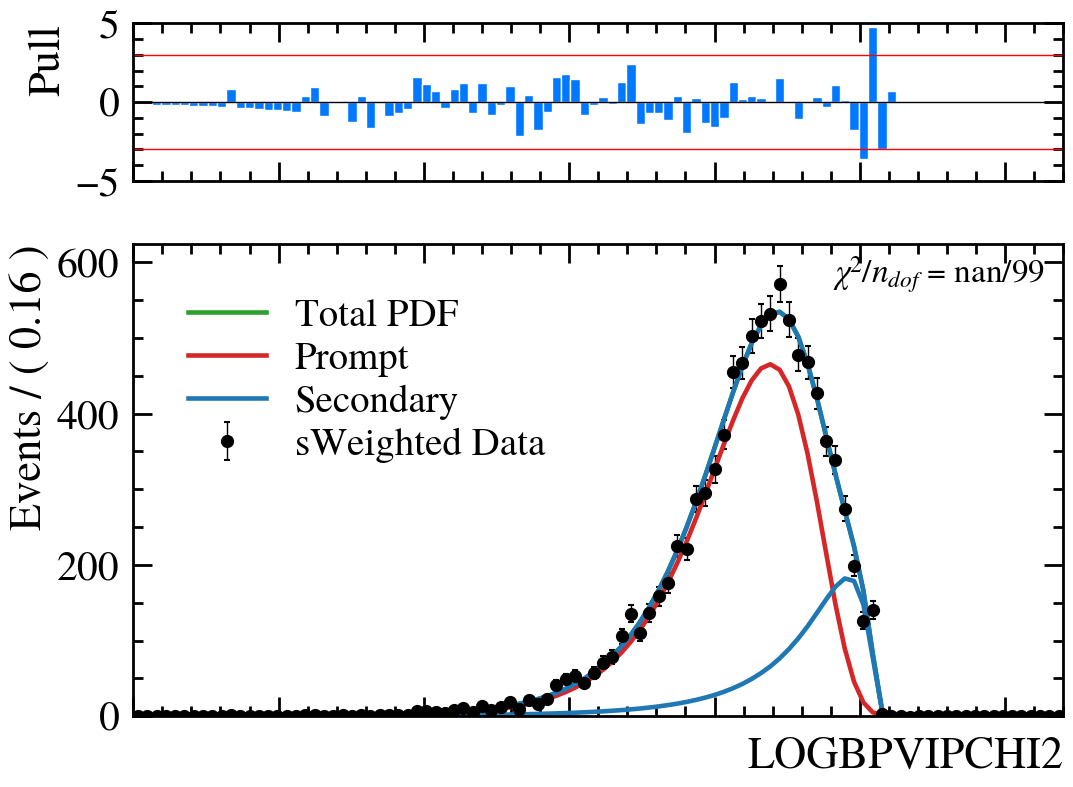

[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::c_sigma
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooRealVar::data_mu_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooFormulaVar::data_lam_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::prompt_mc_sJsu for import of RooFormulaVar::data_lam_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::c_sigma for import of RooFormulaVar::data_lam_P
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) importing RooJohnson::pdf_prompt_data
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::Ds_LOGBPVIPCHI2 for import of RooJohnson::pdf_prompt_data
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooRealVar::data_mu_P for import of RooJohnson::pdf_prompt_data
[#1] INFO:ObjectHandling -- RooWorkspace::import(ws) using existing copy of RooFormulaV

Info in <Minuit2>: MnSeedGenerator Computing seed using NumericalGradient calculator
Info in <Minuit2>: MnSeedGenerator Evaluated function and gradient in 24.6547 ms
Info in <Minuit2>: MnSeedGenerator Initial state: FCN =       15319.04427 Edm =       166027.1875 NCalls =     17
Info in <Minuit2>: NegativeG2LineSearch Doing a NegativeG2LineSearch since one of the G2 component is negative
Info in <Minuit2>: NegativeG2LineSearch Done after 23.6469 ms
Info in <Minuit2>: MnSeedGenerator Negative G2 found - new state: 
  Minimum value : 15228.94448
  Edm           : 21.97744954
  Internal parameters:	[    -0.3398369095      1.143627058    -0.5326027987     0.5235987756]	
  Internal gradient  :	[      194.9037591      58.67598735      623.3762031     -217.3316453]	
  Internal covariance matrix:
[[  8.6601051e-05              0              0              0]
 [              0  0.00031915055              0              0]
 [              0              0  0.00010373679              0]
 [      

In [ ]:
c_sigma = add_to_workspace(ws_ip, r.RooRealVar("c_sigma", "c_sigma", 1.0, 0.5, 2.0))

#PDF to apply c_sigma to the widths of the prompt and secondary components
data_mu_P = add_to_workspace(ws_ip, r.RooRealVar("data_mu_P", 
                                                 "data_mu_P", 
                                                 ws_ip.var('prompt_mc_mJsu').getVal(), 
                                                 -2.0, 4.0))
data_lam_P = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_P", 
                                                     "@0*@1",
                                                       r.RooArgList(ws_ip.var('prompt_mc_sJsu'),
                                                                     c_sigma)))

pdf_prompt_data = add_to_workspace(ws_ip, r.RooJohnson("pdf_prompt_data", 
                                                       "Prompt Data PDF", 
                                                       log_ip,
                                                         data_mu_P,
                                                       data_lam_P, 
                                                       ws_ip.var('prompt_mc_gammaJsu'),
                                                         ws_ip.var('prompt_mc_deltaJsu')))
#for secondary component
data_mu_S = add_to_workspace(ws_ip, r.RooRealVar("data_mu_S",
                                                  "data_mu_S",
                                                    ws_ip.var('sec_mc_mJsu').getVal(),
                                                      2.0, 6.0))

data_lam_S = add_to_workspace(ws_ip, r.RooFormulaVar("data_lam_S", 
                                                     "@0*@1", 
                                                     r.RooArgList(ws_ip.var('sec_mc_sJsu'),
                                                                   c_sigma)))

pdf_sec_data = add_to_workspace(ws_ip, r.RooJohnson("pdf_sec_data",
                                                     "Secondary Data PDF", 
                                                     log_ip,
                                                       data_mu_S, 
                                                       data_lam_S, 
                                                       ws_ip.var('sec_mc_gammaJsu'), 
                                                       ws_ip.var('sec_mc_deltaJsu')))

#model tot
frac_prompt_data = add_to_workspace(ws_ip, r.RooRealVar("frac_prompt_data", 
                                                        "frac_prompt_data",
                                                          0.75, 0.0, 1.0))

model_data_tot = add_to_workspace(ws_ip, r.RooAddPdf("model_data_tot",
                                                      "Total Data PDF", 
                                                      [pdf_prompt_data, pdf_sec_data],
                                                        [frac_prompt_data]))

# Fit data
res_data_ip = fu.fit_to_data(model_data_tot, data_sweight, kSilent=False)

#plot
frame_data = log_ip.frame(r.RooFit.Title(""))
data_sweight.plotOn(frame_data, r.RooFit.DataError(r.RooAbsData.SumW2))
model_data_tot.plotOn(frame_data, r.RooFit.LineColor(r.kGreen))
model_data_tot.plotOn(frame_data, r.RooFit.Components("pdf_prompt_data"), r.RooFit.LineColor(r.kRed))
model_data_tot.plotOn(frame_data, r.RooFit.Components("pdf_sec_data"), r.RooFit.LineColor(r.kBlue))
model_data_tot.plotOn(frame_data) 
fig_data, ax_data = fu.plot_fit_and_residuals_mpl(frame_data, labels=['sWeighted Data', 'Total PDF', 'Prompt', 'Secondary'])
plt.show()

In [35]:
#summury table
n_prompt_mc = len(vals_mcp)
n_sec_mc = len(vals_mcs)
wfraction_initial = n_prompt_mc / (n_prompt_mc + n_sec_mc)

table_data = {
    'wfraction (%)': [f"{wfraction_initial*100}"],
    'MC fit (%)': [f"{frac_prompt_mc.getVal()*100:.2f} ± {frac_prompt_mc.getError()*100:.2f}"],
    'Data fit (%)': [f"{frac_prompt_data.getVal()*100:.2f} ± {frac_prompt_data.getError()*100:.2f}"]
}

df_table21 = pd.DataFrame(table_data)

display(df_table21)
print(f"Correction factor from Data fit (c_sigma): {c_sigma.getVal():.3f} ± {c_sigma.getError():.3f}")

,wfraction (%),MC fit (%),Data fit (%)
0,58.0784974717072,60.72 ± 0.41,79.14 ± 1.67


Correction factor from Data fit (c_sigma): 0.946 ± 0.013


# Check

In [31]:
#check
n_prompt = len(df_MC_ds[df_MC_ds['is_prompt'] == 1])
n_sec = len(df_MC_ds[df_MC_ds['is_prompt'] == 0])
print(n_prompt)
print(n_sec)

frac_sec = n_sec / (n_prompt + n_sec) * 100
print(frac_sec)

43416
31338
41.9215025282928


In [32]:
print(df_MC_ds['Ds_LOGBPVIPCHI2'].max())
print(df_data_ds['Ds_LOGBPVIPCHI2'].max())
#why?

4.5909395
6.219424


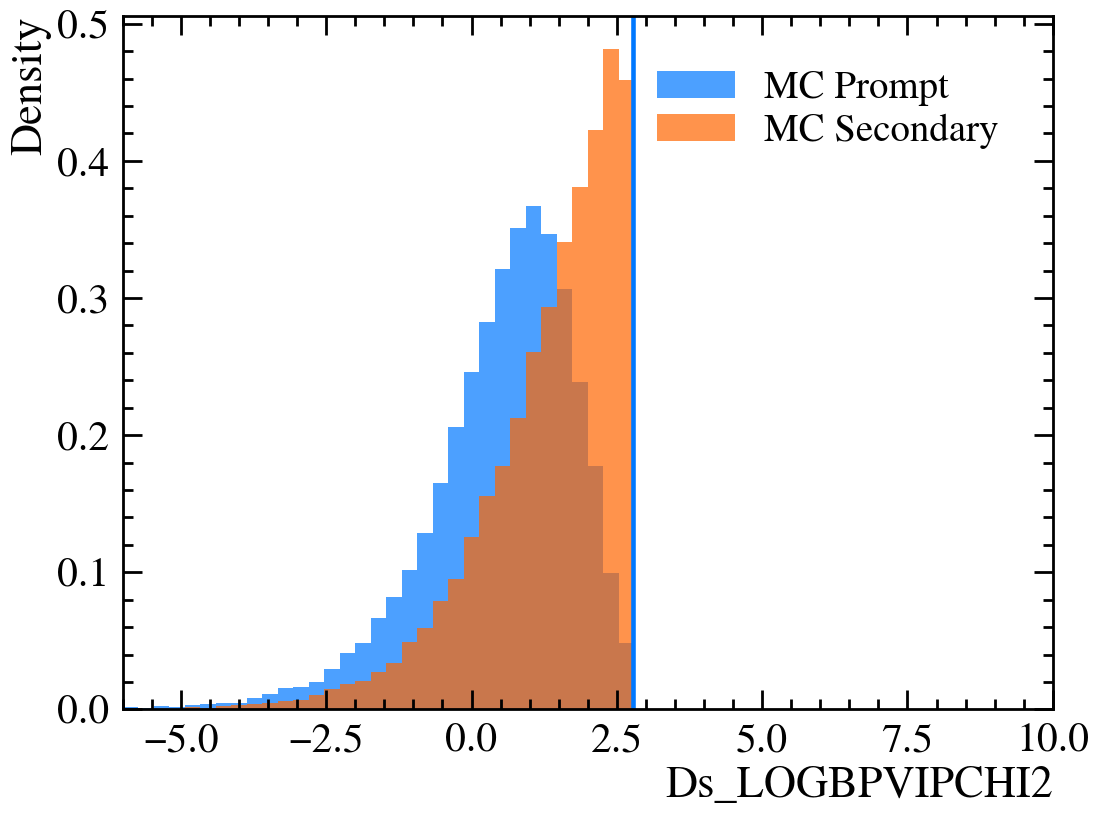

In [33]:
plt.hist(df_MC_ds.loc[df_MC_ds['is_prompt'] == 1, 'Ds_LOGBPVIPCHI2'], bins=60, range=(-6, 10), density=True, alpha=0.7,label='MC Prompt ')
plt.hist(df_MC_ds.loc[df_MC_ds['is_prompt'] == 0, 'Ds_LOGBPVIPCHI2'], bins=60, range=(-6, 10), density=True, alpha=0.7, label='MC Secondary')
plt.axvline(x=np.log(16))
plt.xlabel('Ds_LOGBPVIPCHI2')
plt.ylabel('Density')
plt.legend()
plt.show()

In [34]:
th = np.log(16) 
sup_th= df_MC_ds[df_MC_ds['Ds_LOGBPVIPCHI2'] > th]

print(len(sup_th))
print(len(df_MC_ds))

39
74754
